<a href="https://colab.research.google.com/github/Apurba213/Ostad_AI-Ml-engineering-course/blob/main/Module12_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Feature names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Target names:
['setosa' 'versicolor' 'virginica']

Dataset shape:
(150, 4)
Shape: (150, 5)

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
Species              0
dtype: int64

Statistical summary:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


Species
Setosa        50
Versicolor    50
Virginica     50
Name: count, dtype: int64


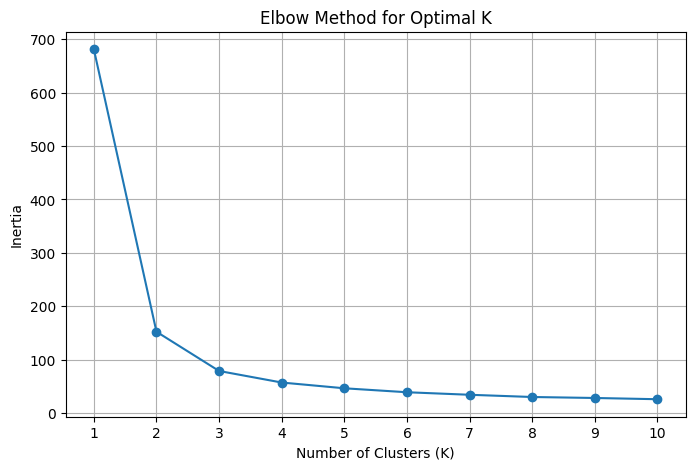

Cluster Labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 0 2 2 2 2 2 0 2 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


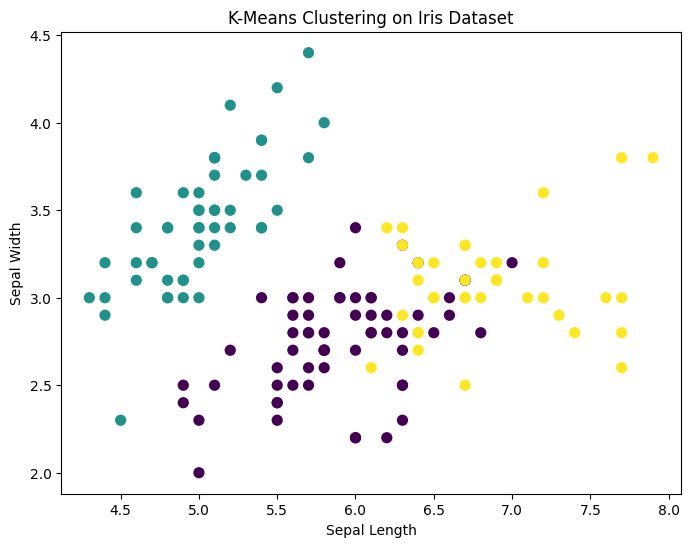

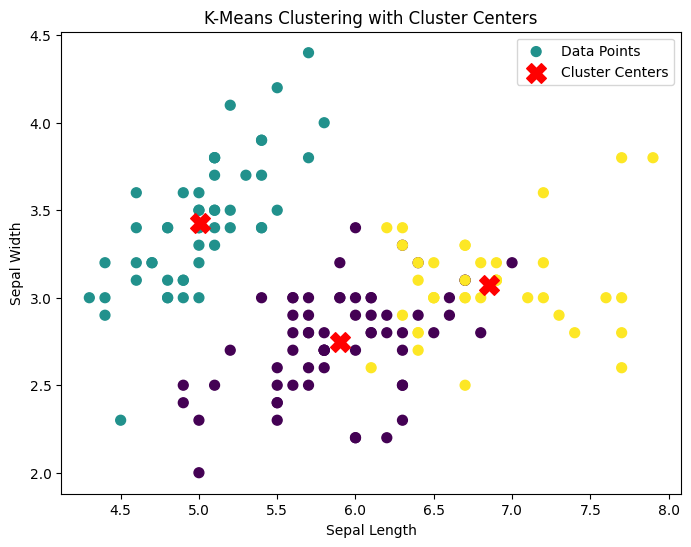

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Section A: K-Means Clustering & Elbow Method
#Task 1 – K-Means & Elbow Method

from sklearn.datasets import load_iris
from sklearn.cluster import KMeans

iris = load_iris()

X = iris.data
y = iris.target

feature_names = iris.feature_names
target_names = iris.target_names

print("Feature names:")
print(feature_names)

print("\nTarget names:")
print(target_names)

print("\nDataset shape:")
print(X.shape)

df = pd.DataFrame(X, columns=feature_names)

df["Species"] = y

df["Species"] = df["Species"].map({
    0: "Setosa",
    1: "Versicolor",
    2: "Virginica"
})

df.head()
print("Shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe())
print(df["Species"].value_counts())
inertia = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X)

    inertia.append(kmeans.inertia_)
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")

plt.xticks(range(1, 11))
plt.grid(True)

plt.show()
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans.fit(X)

clusters = kmeans.labels_

print("Cluster Labels:")
print(clusters)
df["KMeans_Cluster"] = clusters

df.head()
cluster_comparison = pd.crosstab(
    df["Species"],
    df["KMeans_Cluster"]
)

cluster_comparison

plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=clusters,
    cmap="viridis",
    s=50
)

plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.title("K-Means Clustering on Iris Dataset")

plt.show()
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=clusters,
    cmap="viridis",
    s=50,
    label="Data Points"
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    c="red",
    marker="X",
    s=200,
    label="Cluster Centers"
)

plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.title("K-Means Clustering with Cluster Centers")

plt.legend()

plt.show()

Original data shape: (150, 4)
PCA data shape: (150, 2)
Explained Variance Ratio:
[0.92461872 0.05306648]

Total Explained Variance:
0.9776852063187977


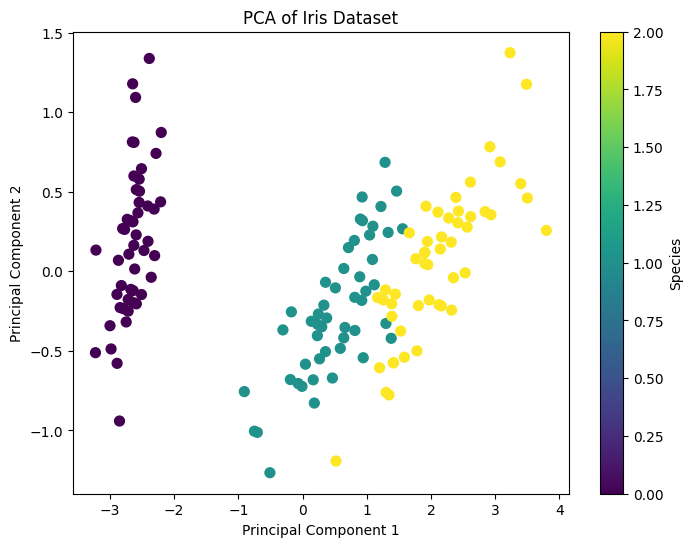

PCA K-Means Cluster Labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 2 0 0 0 0 2 0 0 0 0
 0 0 2 2 0 0 0 0 2 0 2 0 2 0 0 2 2 0 0 0 0 0 2 0 0 0 0 2 0 0 0 2 0 0 0 2 0
 0 2]


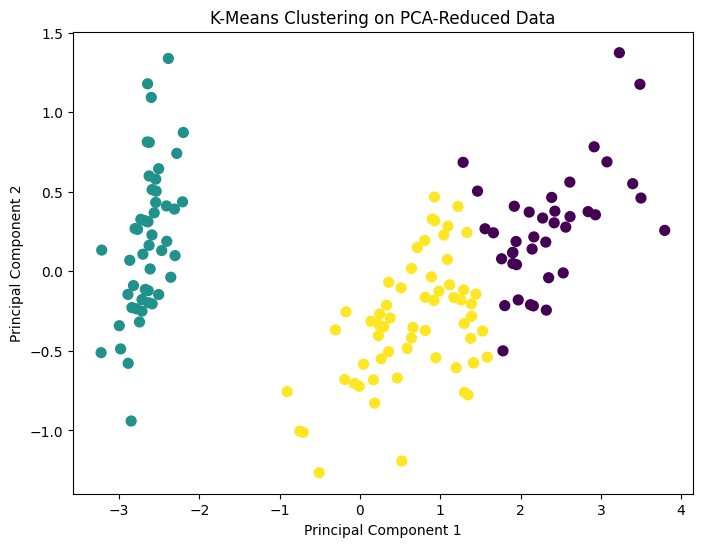

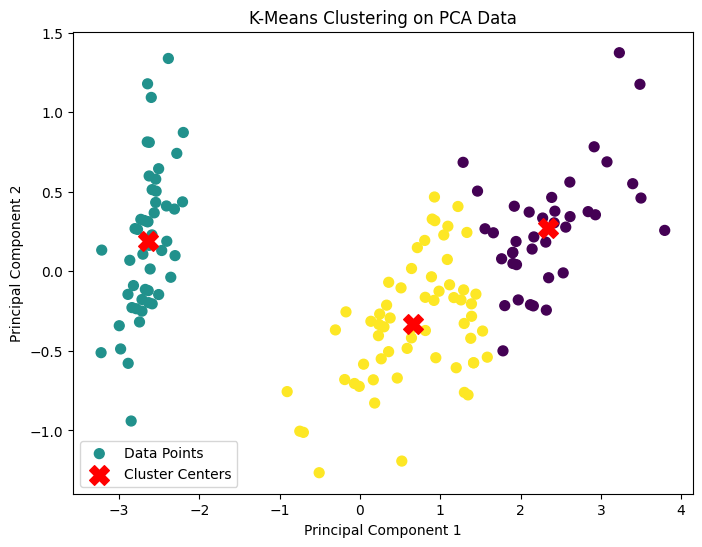

K-Means on Original Data
------------------------
Number of features: 4
Inertia: 78.851441426146

K-Means on PCA Data
-------------------
Number of features: 2
Inertia: 63.81994202200123


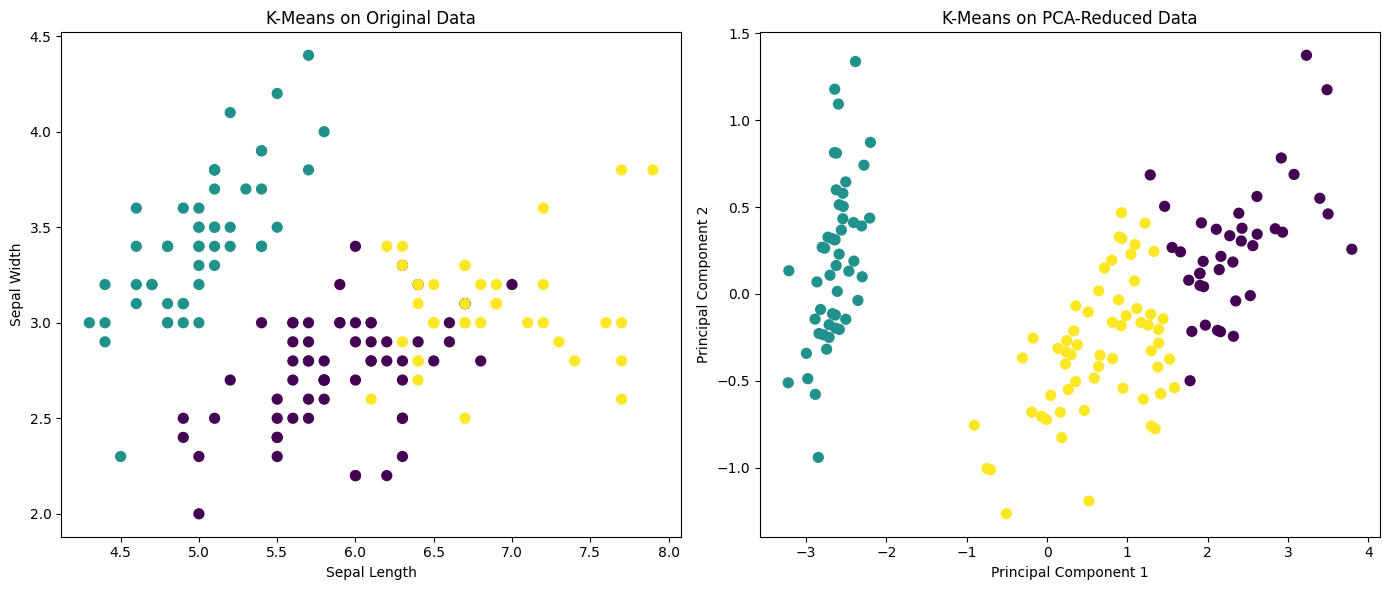

col_0,0,1,2
row_0,,,
0,1,0,61
1,0,50,0
2,38,0,0


In [5]:
#Section B: Principal Component Analysis
#Task 2 – PCA & Visualization

from sklearn.decomposition import PCA
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

print("Original data shape:", X.shape)
print("PCA data shape:", X_pca.shape)
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

pca_df["Species"] = df["Species"]

pca_df.head()

explained_variance = pca.explained_variance_ratio_

print("Explained Variance Ratio:")
print(explained_variance)

print("\nTotal Explained Variance:")
print(explained_variance.sum())

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap="viridis",
    s=50
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of Iris Dataset")

plt.colorbar(label="Species")

plt.show()

kmeans_pca = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_pca.fit(X_pca)

pca_clusters = kmeans_pca.labels_
print("PCA K-Means Cluster Labels:")
print(pca_clusters)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=pca_clusters,
    cmap="viridis",
    s=50
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering on PCA-Reduced Data")

plt.show()
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=pca_clusters,
    cmap="viridis",
    s=50,
    label="Data Points"
)

plt.scatter(
    kmeans_pca.cluster_centers_[:, 0],
    kmeans_pca.cluster_centers_[:, 1],
    c="red",
    marker="X",
    s=200,
    label="Cluster Centers"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering on PCA Data")

plt.legend()

plt.show()

print("K-Means on Original Data")
print("------------------------")
print("Number of features:", X.shape[1])
print("Inertia:", kmeans.inertia_)

print("\nK-Means on PCA Data")
print("-------------------")
print("Number of features:", X_pca.shape[1])
print("Inertia:", kmeans_pca.inertia_)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Original data
axes[0].scatter(
    X[:, 0],
    X[:, 1],
    c=clusters,
    cmap="viridis",
    s=50
)

axes[0].set_xlabel("Sepal Length")
axes[0].set_ylabel("Sepal Width")
axes[0].set_title("K-Means on Original Data")

# PCA data
axes[1].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=pca_clusters,
    cmap="viridis",
    s=50
)

axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")
axes[1].set_title("K-Means on PCA-Reduced Data")

plt.tight_layout()
plt.show()

comparison = pd.crosstab(
    clusters,
    pca_clusters
)

comparison

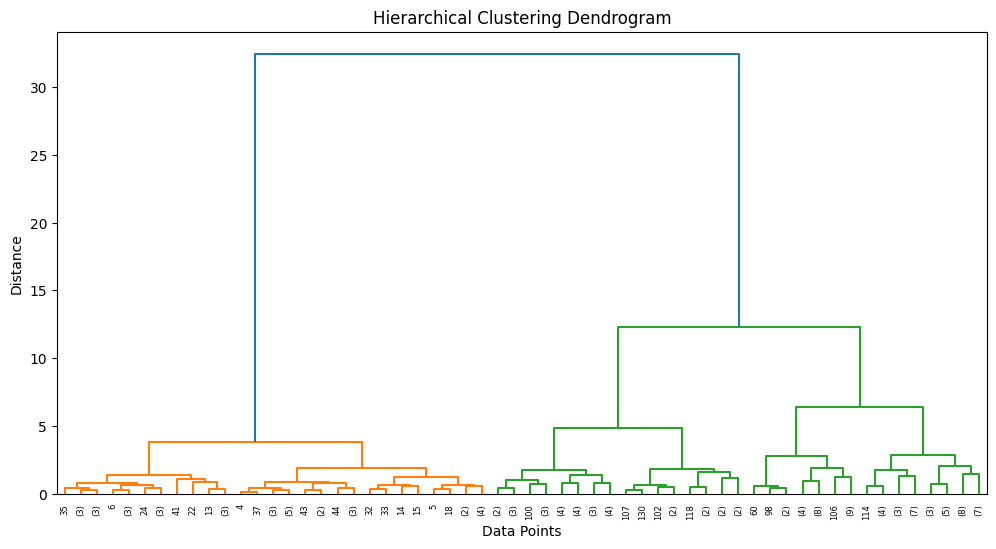

Hierarchical Cluster Labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 0 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


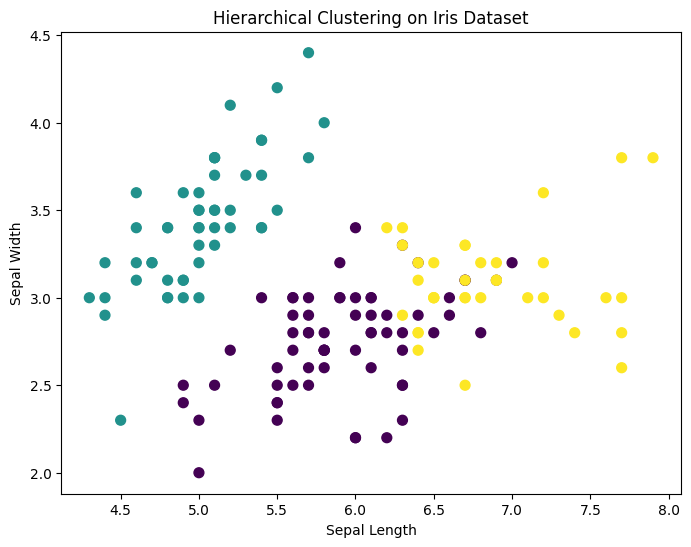

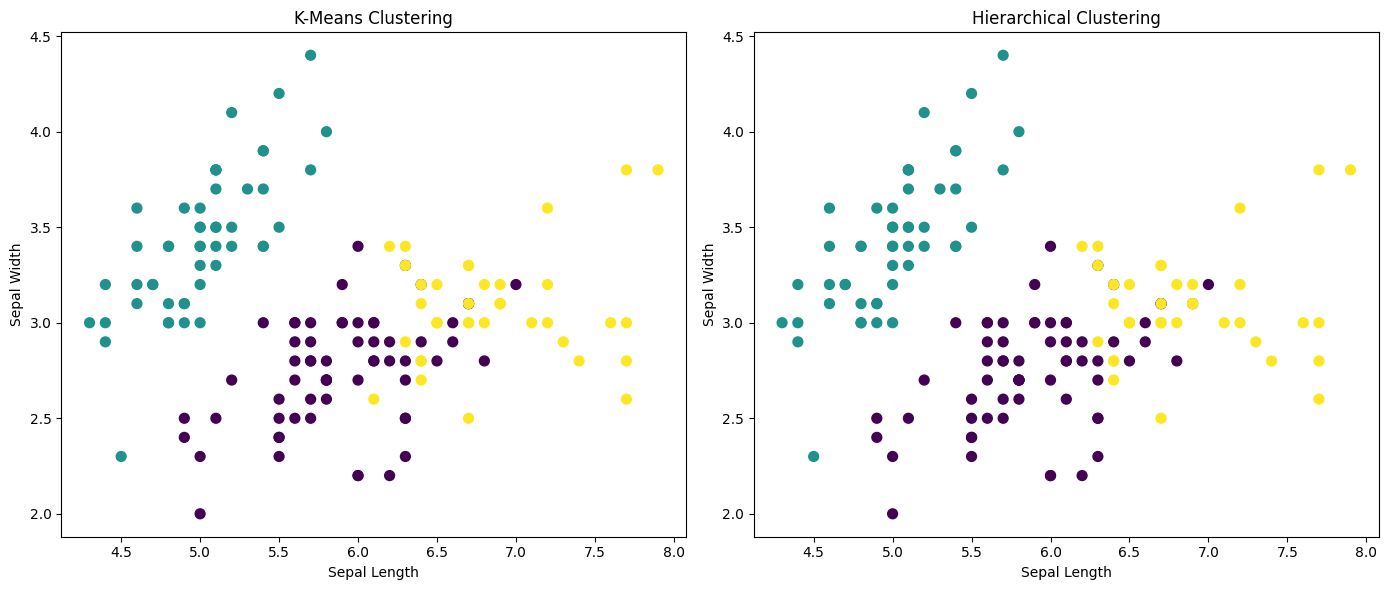

Adjusted Rand Index: 0.9611


In [7]:
#Section C: Hierarchical Clustering
#Task 3 – Hierarchical Clustering & Dendrogram

from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
plt.figure(figsize=(12, 6))

linkage_matrix = linkage(X, method="ward")

dendrogram(
    linkage_matrix,
    truncate_mode="level",
    p=5
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")

plt.show()
hierarchical_model = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

hierarchical_clusters = hierarchical_model.fit_predict(X)

print("Hierarchical Cluster Labels:")
print(hierarchical_clusters)
df["Hierarchical_Cluster"] = hierarchical_clusters

df.head()
hierarchical_comparison = pd.crosstab(
    df["Species"],
    df["Hierarchical_Cluster"]
)

hierarchical_comparison
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=hierarchical_clusters,
    cmap="viridis",
    s=50
)

plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.title("Hierarchical Clustering on Iris Dataset")

plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# K-Means
axes[0].scatter(
    X[:, 0],
    X[:, 1],
    c=clusters,
    cmap="viridis",
    s=50
)

axes[0].set_xlabel("Sepal Length")
axes[0].set_ylabel("Sepal Width")
axes[0].set_title("K-Means Clustering")


# Hierarchical Clustering
axes[1].scatter(
    X[:, 0],
    X[:, 1],
    c=hierarchical_clusters,
    cmap="viridis",
    s=50
)

axes[1].set_xlabel("Sepal Length")
axes[1].set_ylabel("Sepal Width")
axes[1].set_title("Hierarchical Clustering")

plt.tight_layout()
plt.show()

cluster_comparison = pd.crosstab(
    clusters,
    hierarchical_clusters
)

cluster_comparison
from sklearn.metrics import adjusted_rand_score

ari_score = adjusted_rand_score(
    clusters,
    hierarchical_clusters
)

print("Adjusted Rand Index:", round(ari_score, 4))

DBSCAN Cluster Labels:
[ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 -1  0  0  0  0  0  0
  0  0  1  1  1  1  1  1  1 -1  1  1 -1  1  1  1  1  1  1  1 -1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1 -1  1  1  1  1  1 -1  1  1
  1  1 -1  1  1  1  1  1  1 -1 -1  1 -1 -1  1  1  1  1  1  1  1 -1 -1  1
  1  1 -1  1  1  1  1  1  1  1  1 -1  1  1 -1 -1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1]
Cluster labels: {np.int64(0), np.int64(1), np.int64(-1)}
Number of clusters: 2
Number of noise points: 17


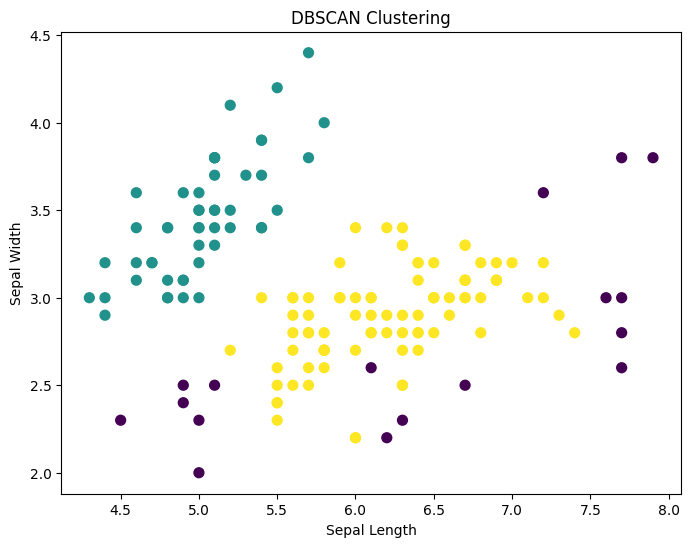

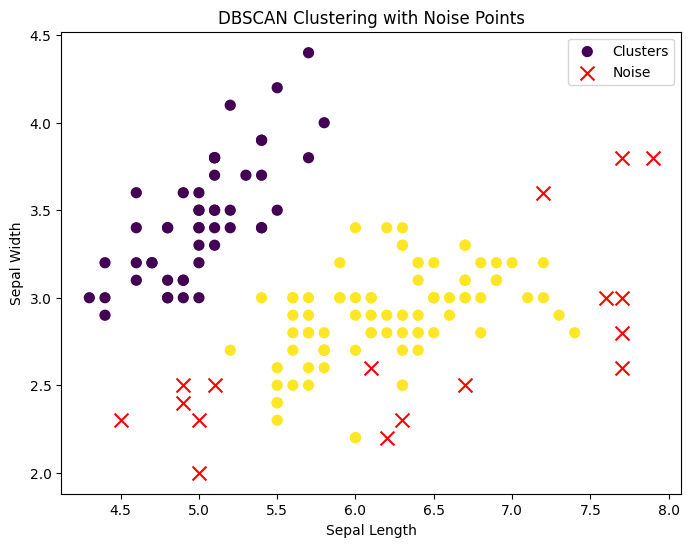

eps=0.3: clusters=3, noise points=96
eps=0.4: clusters=4, noise points=32
eps=0.5: clusters=2, noise points=17
eps=0.6: clusters=2, noise points=9
min_samples=3: clusters=4, noise points=10
min_samples=5: clusters=2, noise points=17
min_samples=7: clusters=2, noise points=24
min_samples=10: clusters=2, noise points=30
min_samples=3: clusters=4, noise points=10
min_samples=5: clusters=2, noise points=17
min_samples=7: clusters=2, noise points=24
min_samples=10: clusters=2, noise points=30


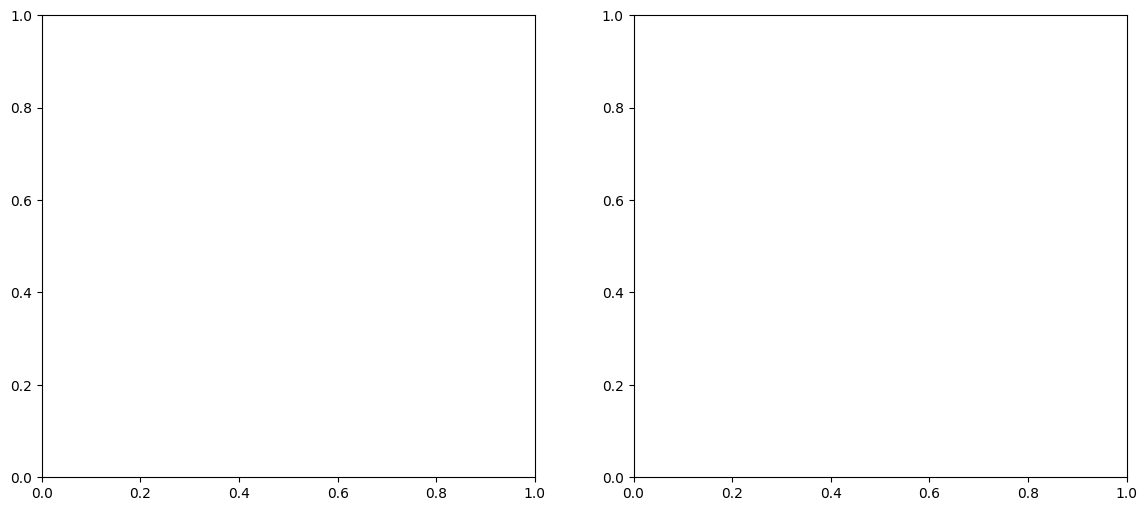

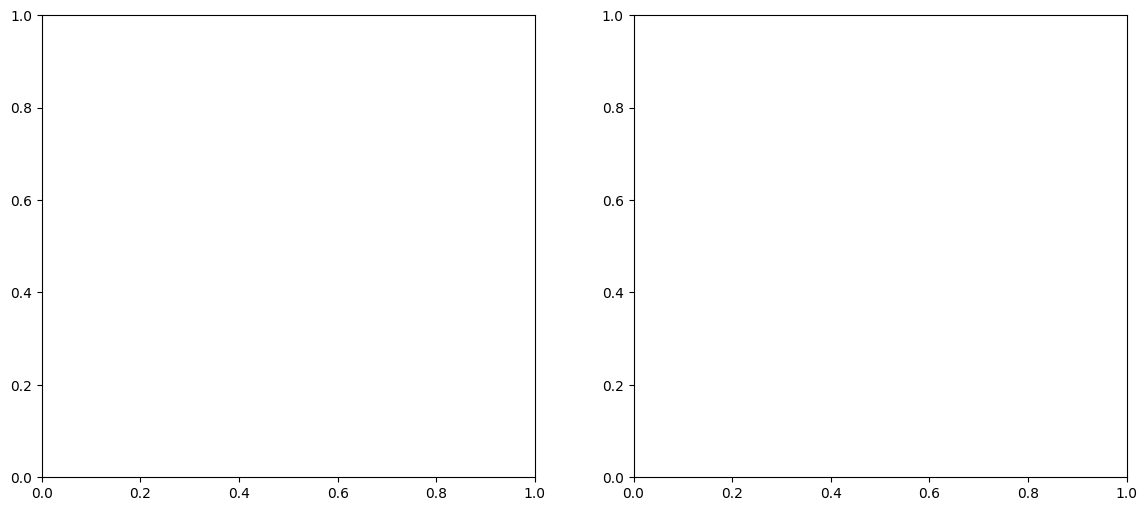

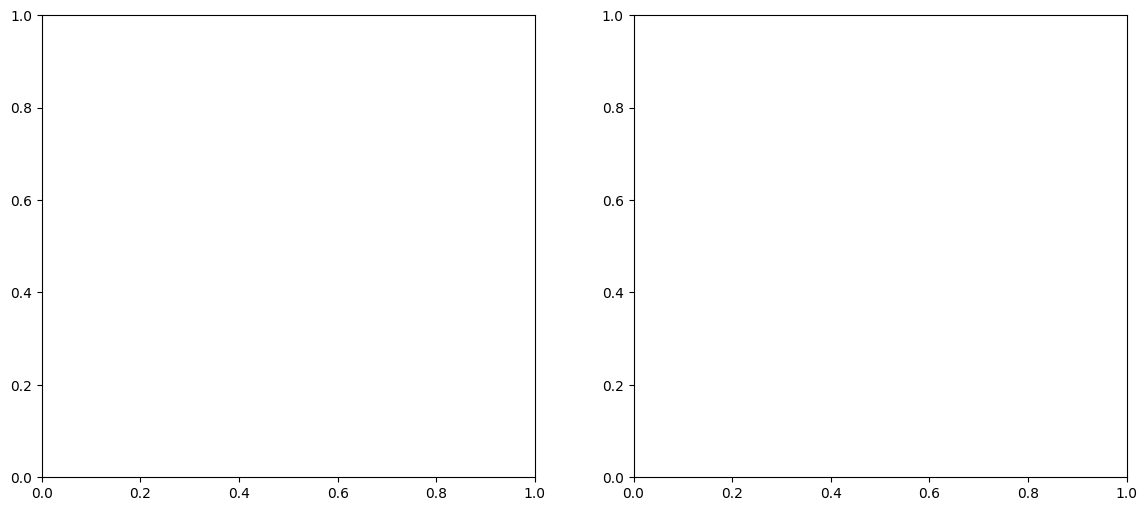

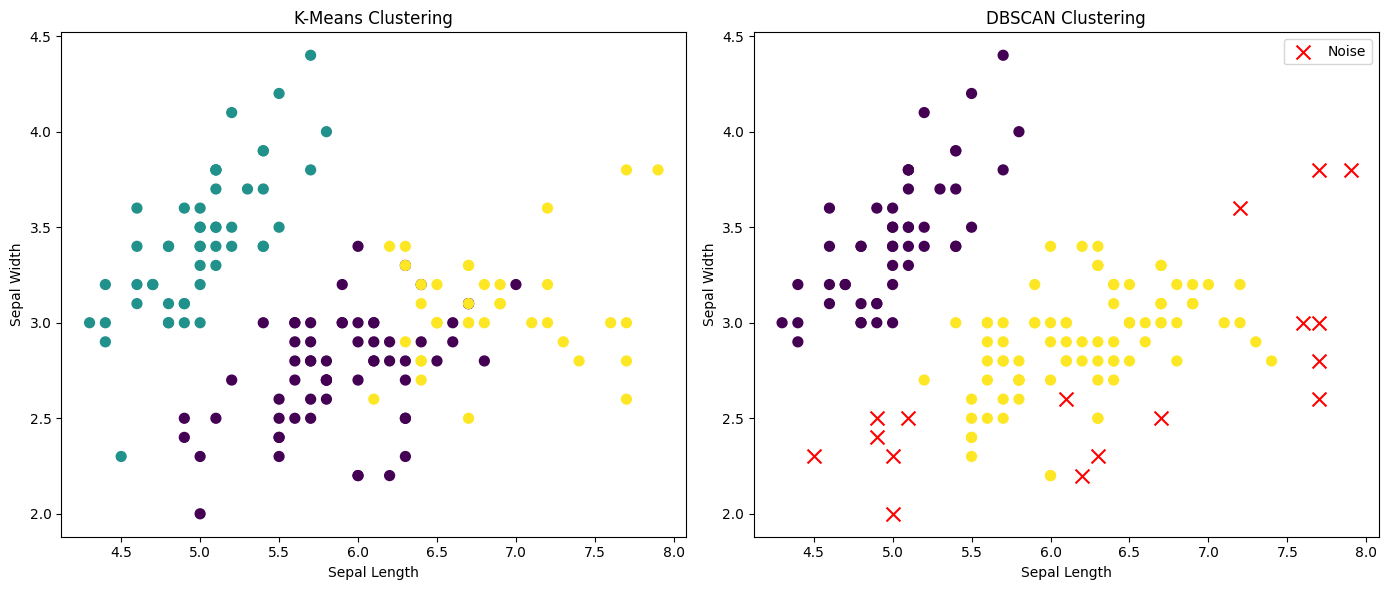

Adjusted Rand Index between K-Means and DBSCAN: 0.5562


col_0,-1,0,1
Species,,,
Setosa,1,49,0
Versicolor,6,0,44
Virginica,10,0,40


In [6]:
#Section D: DBSCAN
#Task 4 – DBSCAN Clustering
from sklearn.cluster import DBSCAN
dbscan = DBSCAN(
    eps=0.5,
    min_samples=5
)

dbscan_clusters = dbscan.fit_predict(X)

print("DBSCAN Cluster Labels:")
print(dbscan_clusters)
unique_labels = set(dbscan_clusters)

print("Cluster labels:", unique_labels)

number_of_clusters = len(
    unique_labels - {-1}
)

number_of_noise = list(
    dbscan_clusters
).count(-1)

print("Number of clusters:", number_of_clusters)
print("Number of noise points:", number_of_noise)
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=dbscan_clusters,
    cmap="viridis",
    s=50
)

plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.title("DBSCAN Clustering")

plt.show()
plt.figure(figsize=(8, 6))

# Non-noise points
non_noise = dbscan_clusters != -1

plt.scatter(
    X[non_noise, 0],
    X[non_noise, 1],
    c=dbscan_clusters[non_noise],
    cmap="viridis",
    s=50,
    label="Clusters"
)

# Noise points
noise = dbscan_clusters == -1

plt.scatter(
    X[noise, 0],
    X[noise, 1],
    c="red",
    marker="x",
    s=100,
    label="Noise"
)

plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.title("DBSCAN Clustering with Noise Points")

plt.legend()

plt.show()
eps_values = [0.3, 0.4, 0.5, 0.6]

for eps in eps_values:

    dbscan_temp = DBSCAN(
        eps=eps,
        min_samples=5
    )

    labels = dbscan_temp.fit_predict(X)

    unique_labels = set(labels)

    n_clusters = len(unique_labels - {-1})
    n_noise = list(labels).count(-1)

    print(
        f"eps={eps}: "
        f"clusters={n_clusters}, "
        f"noise points={n_noise}"
    )
    min_samples_values = [3, 5, 7, 10]

for min_samples in min_samples_values:

    dbscan_temp = DBSCAN(
        eps=0.5,
        min_samples=min_samples
    )

    labels = dbscan_temp.fit_predict(X)

    unique_labels = set(labels)

    n_clusters = len(unique_labels - {-1})
    n_noise = list(labels).count(-1)

    print(
        f"min_samples={min_samples}: "
        f"clusters={n_clusters}, "
        f"noise points={n_noise}"
    )
    min_samples_values = [3, 5, 7, 10]

for min_samples in min_samples_values:

    dbscan_temp = DBSCAN(
        eps=0.5,
        min_samples=min_samples
    )

    labels = dbscan_temp.fit_predict(X)

    unique_labels = set(labels)

    n_clusters = len(unique_labels - {-1})
    n_noise = list(labels).count(-1)

    print(
        f"min_samples={min_samples}: "
        f"clusters={n_clusters}, "
        f"noise points={n_noise}"
    )
    fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 6)
)

# K-Means
axes[0].scatter(
    X[:, 0],
    X[:, 1],
    c=clusters,
    cmap="viridis",
    s=50
)

axes[0].set_xlabel("Sepal Length")
axes[0].set_ylabel("Sepal Width")
axes[0].set_title("K-Means Clustering")


# DBSCAN
non_noise = dbscan_clusters != -1
noise = dbscan_clusters == -1

axes[1].scatter(
    X[non_noise, 0],
    X[non_noise, 1],
    c=dbscan_clusters[non_noise],
    cmap="viridis",
    s=50
)

axes[1].scatter(
    X[noise, 0],
    X[noise, 1],
    c="red",
    marker="x",
    s=100,
    label="Noise"
)

axes[1].set_xlabel("Sepal Length")
axes[1].set_ylabel("Sepal Width")
axes[1].set_title("DBSCAN Clustering")

axes[1].legend()

plt.tight_layout()
plt.show()
from sklearn.metrics import adjusted_rand_score

ari_dbscan = adjusted_rand_score(
    clusters,
    dbscan_clusters
)

print(
    "Adjusted Rand Index between K-Means and DBSCAN:",
    round(ari_dbscan, 4)
)
dbscan_species_comparison = pd.crosstab(
    df["Species"],
    dbscan_clusters
)

dbscan_species_comparison